In [92]:
from google.colab import drive
drive.mount('/gdrive')

Drive already mounted at /gdrive; to attempt to forcibly remount, call drive.mount("/gdrive", force_remount=True).


In [93]:
%cd /gdrive/My Drive/ANNDL_Aielli_Buono_Buranti

/gdrive/My Drive/ANNDL_Aielli_Buono_Buranti


### Import libraries

In [94]:
import tensorflow as tf
import numpy as np
import os
import random
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import shutil
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix
from PIL import Image
from distutils.dir_util import copy_tree

tfk = tf.keras
tfkl = tf.keras.layers
print(tf.__version__)

2.9.2


### Set seed for reproducibility

In [95]:
# Random seed for reproducibility
seed = 42

random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)
tf.random.set_seed(seed)
tf.compat.v1.set_random_seed(seed)

### Suppress warnings

In [96]:
import warnings
import logging

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)
tf.get_logger().setLevel('INFO')
tf.autograph.set_verbosity(0)

tf.get_logger().setLevel(logging.ERROR)
tf.get_logger().setLevel('ERROR')
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)

# Dataset

RGB images of 96X96 pixels. Images belongs to 8 different classes representing plants.

Class labels:
0. Species1
1. Species2
2. Species3
3. Species4
4. Species5
5. Species6
6. Species7
7. Species8

In [97]:
dataset_dir = 'training_data_final'

training_dir = 'training'
validation_dir = 'validation'
test_dir = 'test'
data_augmentation_dir = 'data_augmentation_experiments'
training_data_final = 'training_data_final'

In [98]:
'''if os.path.exists(validation_dir):
    shutil.rmtree(validation_dir)

if os.path.exists(training_dir):
    shutil.rmtree(training_dir)

if os.path.exists(test_dir):
    shutil.rmtree(test_dir)

if os.path.exists(training_data_final):
    shutil.rmtree(training_data_final)
'''

'if os.path.exists(validation_dir):\n    shutil.rmtree(validation_dir)\n\nif os.path.exists(training_dir):\n    shutil.rmtree(training_dir)\n\nif os.path.exists(test_dir):\n    shutil.rmtree(test_dir)\n\nif os.path.exists(training_data_final):\n    shutil.rmtree(training_data_final)\n'

In [99]:
#if os.path.exists(data_augmentation_dir):
#    shutil.rmtree(data_augmentation_dir)

In [100]:
# Load the dataset to be used for classification
#!unzip training_dataset_homework1.zip

In [101]:
#if not os.path.exists(validation_dir):
#    os.mkdir(validation_dir)

#if not os.path.exists(training_dir):
#    os.mkdir(training_dir)

#if not os.path.exists(test_dir):
#    os.mkdir(test_dir)

In [102]:
#shutil.copytree(dataset_dir, training_dir) 
#copy_tree(dataset_dir, training_dir)

In [103]:
img_size = 96
input_shape = (img_size, img_size, 3)
batch_size = 16

In [104]:
'''for subdir, dirs, files in os.walk(training_dir):
    for class_dir in dirs:
        filenames = os.listdir(os.path.join(training_dir, class_dir))
        np.random.shuffle(filenames)
        split_training_validation = int(0.8 * len(filenames))
        split_validation_test = int(0.9 * len(filenames))

        train_filenames = filenames[:split_training_validation]
        valid_filenames = filenames[split_training_validation:split_validation_test]
        test_filenames = filenames[split_validation_test:]

        if not os.path.exists(os.path.join(validation_dir, class_dir)):
            os.mkdir(os.path.join(validation_dir, class_dir))
        for file in valid_filenames:
            shutil.move(os.path.join(training_dir, class_dir, file), os.path.join(validation_dir, class_dir, file))
        if not os.path.exists(os.path.join(test_dir, class_dir)):
            os.mkdir(os.path.join(test_dir, class_dir))
        for file in test_filenames:
            shutil.move(os.path.join(training_dir, class_dir, file), os.path.join(test_dir, class_dir, file))
'''

'for subdir, dirs, files in os.walk(training_dir):\n    for class_dir in dirs:\n        filenames = os.listdir(os.path.join(training_dir, class_dir))\n        np.random.shuffle(filenames)\n        split_training_validation = int(0.8 * len(filenames))\n        split_validation_test = int(0.9 * len(filenames))\n\n        train_filenames = filenames[:split_training_validation]\n        valid_filenames = filenames[split_training_validation:split_validation_test]\n        test_filenames = filenames[split_validation_test:]\n\n        if not os.path.exists(os.path.join(validation_dir, class_dir)):\n            os.mkdir(os.path.join(validation_dir, class_dir))\n        for file in valid_filenames:\n            shutil.move(os.path.join(training_dir, class_dir, file), os.path.join(validation_dir, class_dir, file))\n        if not os.path.exists(os.path.join(test_dir, class_dir)):\n            os.mkdir(os.path.join(test_dir, class_dir))\n        for file in test_filenames:\n            shutil.mov

In [ ]:
'''# Plot example images from dataset
labels = ['Species1',       # 0
          'Species2',           # 1
          'Species3',    # 2
          'Species4',              # 3
          'Species5',          # 4
          'Species6',          # 5
          'Species7',   # 6
          'Species8']           #7

num_row = 4
num_col = 2
fig, axes = plt.subplots(num_row, num_col, figsize=(2*num_row,9*num_col))
for i in range(num_row*num_col):
  if i < 8:
    class_imgs = next(os.walk('{}/{}'.format(training_dir, labels[i])))[2]
    class_img = class_imgs[0]
    img = Image.open('{}/{}/{}'.format(training_dir, labels[i], class_img))
    ax = axes[i//num_col, i%num_col]
    ax.imshow(np.array(img))
    ax.set_title('{}'.format(labels[i]))
plt.tight_layout()
plt.show()
'''

# Data Loader

### Typically, data is too large to be loaded as a NumPy array.
### We need a different strategy..

In [106]:
# Images are divided into folders, one for each class. 
# If the images are organized in such a way, we can exploit the 
# ImageDataGenerator to read them from disk.
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create an instance of ImageDataGenerator for training, validation, and test sets
train_data_gen = ImageDataGenerator()
valid_data_gen = ImageDataGenerator()
test_data_gen = ImageDataGenerator()

# Obtain a data generator with the 'ImageDataGenerator.flow_from_directory' method
train_gen = train_data_gen.flow_from_directory(directory=training_dir,
                                               target_size=(img_size,img_size),
                                               color_mode='rgb',
                                               classes=None, # can be set to labels
                                               class_mode='categorical',
                                               batch_size=8,
                                               shuffle=True,
                                               seed=seed)
valid_gen = train_data_gen.flow_from_directory(directory=validation_dir,
                                               target_size=(img_size,img_size),
                                               color_mode='rgb',
                                               classes=None, # can be set to labels
                                               class_mode='categorical',
                                               batch_size=8,
                                               shuffle=False,
                                               seed=seed)
test_gen = train_data_gen.flow_from_directory(directory=test_dir,
                                              target_size=(img_size,img_size),
                                              color_mode='rgb',
                                              classes=None, # can be set to labels
                                              class_mode='categorical',
                                              batch_size=8,
                                              shuffle=False,
                                              seed=seed)

Found 2829 images belonging to 8 classes.
Found 354 images belonging to 8 classes.
Found 359 images belonging to 8 classes.


In [107]:
print("Assigned labels")
print(train_gen.class_indices)
print()
print("Target classes")
print(train_gen.classes)

Assigned labels
{'Species1': 0, 'Species2': 1, 'Species3': 2, 'Species4': 3, 'Species5': 4, 'Species6': 5, 'Species7': 6, 'Species8': 7}

Target classes
[0 0 0 ... 7 7 7]


In [108]:
def get_next_batch(generator):
  batch = next(generator)

  image = batch[0]
  target = batch[1]

  print("(Input) image shape:", image.shape)
  print("Target shape:",target.shape)

  # Visualize only the first sample
  image = image[0]
  target = target[0]
  target_idx = np.argmax(target)
  print()
  print("Categorical label:", target)
  print("Label:", target_idx)
  print("Class name:", labels[target_idx])
  fig = plt.figure(figsize=(6, 4))
  plt.imshow(np.uint8(image))

  return batch

(Input) image shape: (8, 96, 96, 3)
Target shape: (8, 8)

Categorical label: [0. 0. 0. 1. 0. 0. 0. 0.]
Label: 3
Class name: Species4


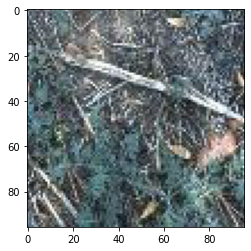

In [109]:
# Get a sample from dataset and show info
_ = get_next_batch(train_gen)

# Data Augmentation

##### ImageDataGenerator allows to perform data augmentation

```
tf.keras.preprocessing.image.ImageDataGenerator(
    featurewise_center=False, samplewise_center=False,
    featurewise_std_normalization=False, samplewise_std_normalization=False,
    zca_whitening=False, zca_epsilon=1e-06, rotation_range=0, width_shift_range=0.0,
    height_shift_range=0.0, brightness_range=None, shear_range=0.0, zoom_range=0.0,
    channel_shift_range=0.0, fill_mode='nearest', cval=0.0,
    horizontal_flip=False, vertical_flip=False, rescale=None,
    preprocessing_function=None, data_format=None, validation_split=0.0, dtype=None
)
```

Rotation: {'theta': -7.527592869158251, 'tx': 0, 'ty': 0, 'shear': 0, 'zx': 1, 'zy': 1, 'flip_horizontal': 0, 'flip_vertical': 0, 'channel_shift_intensity': None, 'brightness': None} 

Shift: {'theta': 0, 'tx': 0, 'ty': 38, 'shear': 0, 'zx': 1, 'zy': 1, 'flip_horizontal': 0, 'flip_vertical': 0, 'channel_shift_intensity': None, 'brightness': None} 

Zoom: {'theta': 0, 'tx': 0, 'ty': 0, 'shear': 0, 'zx': 0.9247240713084175, 'zy': 1.2704285838459497, 'flip_horizontal': 0, 'flip_vertical': 0, 'channel_shift_intensity': None, 'brightness': None} 

Flip: {'theta': 0, 'tx': 0, 'ty': 0, 'shear': 0, 'zx': 1, 'zy': 1, 'flip_horizontal': 1, 'flip_vertical': 0, 'channel_shift_intensity': None, 'brightness': None} 



Text(0.5, 1.0, 'Flipped')

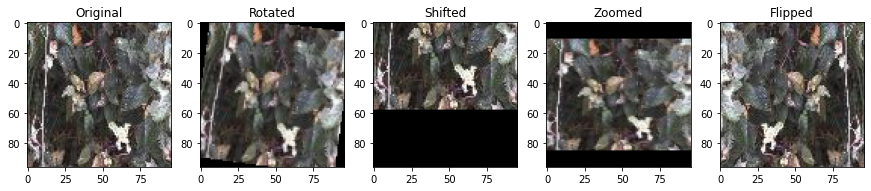

In [110]:
# Create some augmentation examples
# Get sample image
image = next(train_gen)[0][4]

# Create an instance of ImageDataGenerator for each transformation
rot_gen = ImageDataGenerator(rotation_range=30)
shift_gen = ImageDataGenerator(width_shift_range=50)
zoom_gen = ImageDataGenerator(zoom_range=0.3)
flip_gen = ImageDataGenerator(horizontal_flip=True)

# Get random transformations
rot_t = rot_gen.get_random_transform(img_shape=(img_size, img_size), seed=seed)
print('Rotation:', rot_t, '\n')
shift_t = shift_gen.get_random_transform(img_shape=(img_size, img_size), seed=seed)
print('Shift:', shift_t, '\n')
zoom_t = zoom_gen.get_random_transform(img_shape=(img_size, img_size), seed=seed)
print('Zoom:', zoom_t, '\n')
flip_t = flip_gen.get_random_transform(img_shape=(img_size, img_size), seed=seed)
print('Flip:', flip_t, '\n')

# Apply the transformation
gen = ImageDataGenerator(fill_mode='constant', cval=0.)
rotated = gen.apply_transform(image, rot_t)
shifted = gen.apply_transform(image, shift_t) 
zoomed = gen.apply_transform(image, zoom_t) 
flipped = gen.apply_transform(image, flip_t)  

# Plot original and augmented images
fig, ax = plt.subplots(1, 5, figsize=(15, 45))
ax[0].imshow(np.uint8(image))
ax[0].set_title('Original')
ax[1].imshow(np.uint8(rotated))
ax[1].set_title('Rotated')
ax[2].imshow(np.uint8(shifted))
ax[2].set_title('Shifted')
ax[3].imshow(np.uint8(zoomed))
ax[3].set_title('Zoomed')
ax[4].imshow(np.uint8(flipped))
ax[4].set_title('Flipped')

Transform: {'theta': -7.527592869158251, 'tx': -28, 'ty': 42, 'shear': 0, 'zx': 1.059195090518222, 'zy': 0.7936111842654618, 'flip_horizontal': 1, 'flip_vertical': 1, 'channel_shift_intensity': None, 'brightness': None}


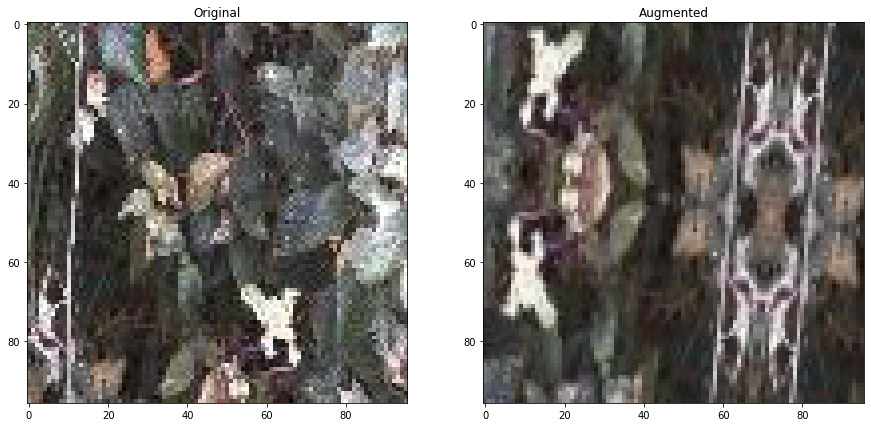

In [111]:
# Combine multiple transformations
gen = ImageDataGenerator(rotation_range=30,
                         height_shift_range=50,
                         width_shift_range=50,
                         zoom_range=0.3,
                         horizontal_flip=True,
                         vertical_flip=True, 
                         fill_mode='reflect')

# Get random transformation
t = gen.get_random_transform(img_shape=(img_size, img_size), seed=seed)
print("Transform:", t)

# Apply the transformation
augmented = gen.apply_transform(image, t)

# Plot original and augmented images
fig, ax = plt.subplots(1, 2, figsize=(15,30))
ax[0].imshow(np.uint8(image))
ax[0].set_title("Original")
ax[1].imshow(np.uint8(augmented))
ax[1].set_title("Augmented")
plt.show()

# Training with and without data augmentation

In [112]:
# Create an instance of ImageDataGenerator with NO Data Augmentation
noaug_train_data_gen = ImageDataGenerator(rescale=1/255.) # rescale value is multiplied to the image
valid_data_gen = ImageDataGenerator(rescale=1/255.)
test_data_gen = ImageDataGenerator(rescale=1/255.)

# Obtain a data generator with the 'ImageDataGenerator.flow_from_directory' method
noaug_train_gen = noaug_train_data_gen.flow_from_directory(directory=training_dir,
                                                           target_size=(img_size,img_size),
                                                           color_mode='rgb',
                                                           classes=None, # can be set to labels
                                                           class_mode='categorical',
                                                           batch_size=8,
                                                           shuffle=True,
                                                           seed=seed)
valid_gen = valid_data_gen.flow_from_directory(directory=validation_dir,
                                               target_size=(img_size,img_size),
                                               color_mode='rgb',
                                               classes=None, # can be set to labels
                                               class_mode='categorical',
                                               batch_size=8,
                                               shuffle=False,
                                               seed=seed)
test_gen = test_data_gen.flow_from_directory(directory=test_dir,
                                             target_size=(img_size,img_size),
                                             color_mode='rgb',
                                             classes=None, # can be set to labels
                                             class_mode='categorical',
                                             batch_size=8,
                                             shuffle=False,
                                             seed=seed)

Found 2829 images belonging to 8 classes.
Found 354 images belonging to 8 classes.
Found 359 images belonging to 8 classes.


In [113]:
# Create an instance of ImageDataGenerator with Data Augmentation
aug_train_data_gen = ImageDataGenerator(rotation_range=30,
                                        height_shift_range=50,
                                        width_shift_range=50,
                                        zoom_range=0.3,
                                        horizontal_flip=True,
                                        vertical_flip=True, 
                                        fill_mode='reflect',
                                        rescale=1/255.) # rescale value is multiplied to the image

# Obtain a data generator with the 'ImageDataGenerator.flow_from_directory' method
aug_train_gen = aug_train_data_gen.flow_from_directory(directory=training_dir,
                                                       target_size=(img_size,img_size),
                                                       color_mode='rgb',
                                                       classes=None, # can be set to labels
                                                       class_mode='categorical',
                                                       batch_size=8,
                                                       shuffle=True,
                                                       seed=seed)

Found 2829 images belonging to 8 classes.


### Models metadata

In [114]:
input_shape = (img_size, img_size, 3)
epochs = 200

In [115]:
def build_model(input_shape):

    # Build the neural network layer by layer
    input_layer = tfkl.Input(shape=input_shape, name='input_layer')

    conv1 = tfkl.Conv2D(
        filters=32,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(input_layer)
    pool1 = tfkl.MaxPooling2D()(conv1)

    conv2 = tfkl.Conv2D(
        filters=64,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(pool1)
    pool2 = tfkl.MaxPooling2D()(conv2)

    conv3 = tfkl.Conv2D(
        filters=128,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(pool2)
    pool3 = tfkl.MaxPooling2D()(conv3)

    conv4 = tfkl.Conv2D(
        filters=256,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(pool3)
    pool4 = tfkl.MaxPooling2D()(conv4)

    conv5 = tfkl.Conv2D(
        filters=512,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(pool4)
    pool5 = tfkl.MaxPooling2D()(conv5)

    flattening_layer = tfkl.Flatten(name='Flatten')(pool5)
    dropout = tfkl.Dropout(0.3, seed=seed)(flattening_layer)
    classifier_layer = tfkl.Dense(units=512, name='Classifier', kernel_initializer=tfk.initializers.HeUniform(seed), activation='relu')(dropout)
    dropout = tfkl.Dropout(0.3, seed=seed)(classifier_layer)
    output_layer = tfkl.Dense(units=8, activation='softmax', kernel_initializer=tfk.initializers.GlorotUniform(seed), name='output_layer')(dropout)

    # Connect input and output through the Model class
    model = tfk.Model(inputs=input_layer, outputs=output_layer, name='model')

    # Compile the model
    model.compile(loss=tfk.losses.CategoricalCrossentropy(), optimizer=tfk.optimizers.Adam(), metrics='accuracy')

    # Return the model
    return model

In [116]:
# Utility function to create folders and callbacks for training
from datetime import datetime

def create_folders_and_callbacks(model_name):

  exps_dir = os.path.join('data_augmentation_experiments')
  if not os.path.exists(exps_dir):
      os.makedirs(exps_dir)

  now = datetime.now().strftime('%b%d_%H-%M-%S')

  exp_dir = os.path.join(exps_dir, model_name + '_' + str(now))
  if not os.path.exists(exp_dir):
      os.makedirs(exp_dir)
      
  callbacks = []

  # Model checkpoint
  # ----------------
  ckpt_dir = os.path.join(exp_dir, 'ckpts')
  if not os.path.exists(ckpt_dir):
      os.makedirs(ckpt_dir)

  ckpt_callback = tf.keras.callbacks.ModelCheckpoint(filepath=os.path.join(ckpt_dir, 'cp.ckpt'), 
                                                     save_weights_only=True, # True to save only weights
                                                     save_best_only=False) # True to save only the best epoch 
  callbacks.append(ckpt_callback)

  # Visualize Learning on Tensorboard
  # ---------------------------------
  tb_dir = os.path.join(exp_dir, 'tb_logs')
  if not os.path.exists(tb_dir):
      os.makedirs(tb_dir)
      
  # By default shows losses and metrics for both training and validation
  tb_callback = tf.keras.callbacks.TensorBoard(log_dir=tb_dir, 
                                               profile_batch=0,
                                               histogram_freq=1)  # if > 0 (epochs) shows weights histograms
  callbacks.append(tb_callback)

  # Early Stopping
  # --------------
  es_callback = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)
  callbacks.append(es_callback)

  return callbacks

In [117]:
# Build model (for NO augmentation training)
model = build_model(input_shape)
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_layer (InputLayer)    [(None, 96, 96, 3)]       0         
                                                                 
 conv2d_20 (Conv2D)          (None, 96, 96, 32)        896       
                                                                 
 max_pooling2d_20 (MaxPoolin  (None, 48, 48, 32)       0         
 g2D)                                                            
                                                                 
 conv2d_21 (Conv2D)          (None, 48, 48, 64)        18496     
                                                                 
 max_pooling2d_21 (MaxPoolin  (None, 24, 24, 64)       0         
 g2D)                                                            
                                                                 
 conv2d_22 (Conv2D)          (None, 24, 24, 128)       73856 

In [118]:
# Create folders and callbacks and fit
noaug_callbacks = create_folders_and_callbacks(model_name='CNN_NoAug')

# Train the model
history = model.fit(
    x = noaug_train_gen,
    epochs = epochs,
    validation_data = valid_gen,
    callbacks = noaug_callbacks,
).history

Epoch 1/200
354/354 [==============================] - 9s 25ms/step - loss: 1.9768 - accuracy: 0.2527 - val_loss: 1.6409 - val_accuracy: 0.2655
Epoch 2/200
354/354 [==============================] - 9s 24ms/step - loss: 1.6371 - accuracy: 0.3510 - val_loss: 1.4638 - val_accuracy: 0.4661
Epoch 3/200
354/354 [==============================] - 10s 27ms/step - loss: 1.5116 - accuracy: 0.4023 - val_loss: 1.4547 - val_accuracy: 0.4040
Epoch 4/200
354/354 [==============================] - 9s 25ms/step - loss: 1.4020 - accuracy: 0.4464 - val_loss: 1.3433 - val_accuracy: 0.4492
Epoch 5/200
354/354 [==============================] - 9s 24ms/step - loss: 1.2693 - accuracy: 0.4981 - val_loss: 1.2536 - val_accuracy: 0.4859
Epoch 6/200
354/354 [==============================] - 9s 25ms/step - loss: 1.1997 - accuracy: 0.5338 - val_loss: 1.2513 - val_accuracy: 0.4972
Epoch 7/200
354/354 [==============================] - 9s 26ms/step - loss: 1.1375 - accuracy: 0.5620 - val_loss: 1.3243 - val_accuracy

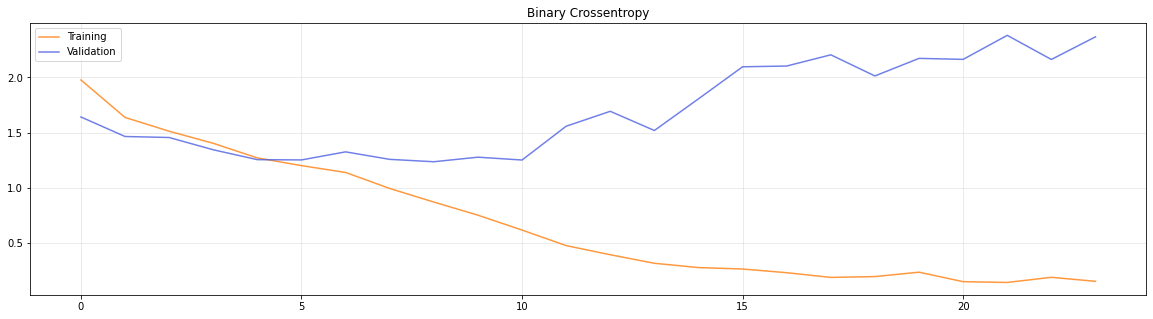

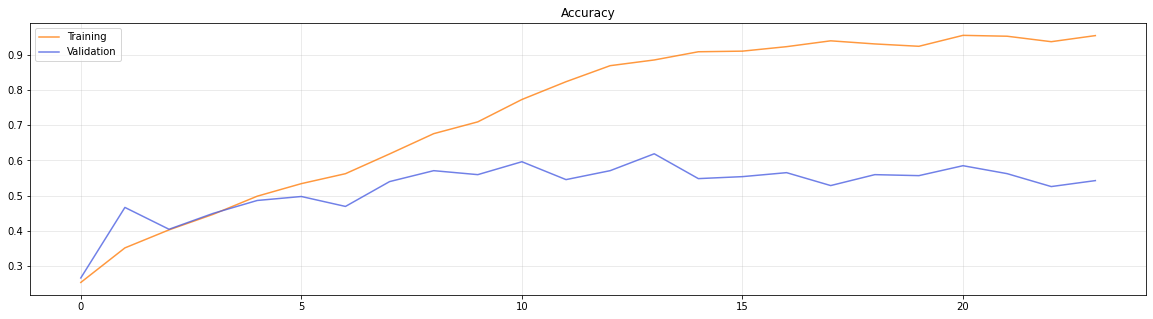

In [119]:
# Plot the training
plt.figure(figsize=(20,5))
plt.plot(history['loss'], label='Training', alpha=.8, color='#ff7f0e')
plt.plot(history['val_loss'], label='Validation', alpha=.8, color='#4D61E2')
plt.legend(loc='upper left')
plt.title('Binary Crossentropy')
plt.grid(alpha=.3)

plt.figure(figsize=(20,5))
plt.plot(history['accuracy'], label='Training', alpha=.8, color='#ff7f0e')
plt.plot(history['val_accuracy'], label='Validation', alpha=.8, color='#4D61E2')
plt.legend(loc='upper left')
plt.title('Accuracy')
plt.grid(alpha=.3)

plt.show()

In [120]:
# Save best epoch model
model.save("data_augmentation_experiments/CNN_NoAug_Best")

In [121]:
# Build model (for data augmentation training)
model = build_model(input_shape)

In [122]:
# Create folders and callbacks and fit
aug_callbacks = create_folders_and_callbacks(model_name='CNN_Aug')

# Train the model
history = model.fit(
    x = aug_train_gen,
    epochs = epochs,
    validation_data = valid_gen,
    callbacks = aug_callbacks,
).history

Epoch 1/200
354/354 [==============================] - 16s 45ms/step - loss: 2.0611 - accuracy: 0.2174 - val_loss: 2.6212 - val_accuracy: 0.1469
Epoch 2/200
354/354 [==============================] - 16s 44ms/step - loss: 1.8508 - accuracy: 0.2828 - val_loss: 2.3809 - val_accuracy: 0.1751
Epoch 3/200
354/354 [==============================] - 17s 47ms/step - loss: 1.7063 - accuracy: 0.3178 - val_loss: 2.0512 - val_accuracy: 0.2288
Epoch 4/200
354/354 [==============================] - 15s 43ms/step - loss: 1.6652 - accuracy: 0.3436 - val_loss: 2.4874 - val_accuracy: 0.2232
Epoch 5/200
354/354 [==============================] - 15s 43ms/step - loss: 1.5384 - accuracy: 0.4150 - val_loss: 1.8225 - val_accuracy: 0.2853
Epoch 6/200
354/354 [==============================] - 16s 46ms/step - loss: 1.4595 - accuracy: 0.4556 - val_loss: 1.6853 - val_accuracy: 0.3588
Epoch 7/200
354/354 [==============================] - 16s 44ms/step - loss: 1.3902 - accuracy: 0.4747 - val_loss: 1.6086 - val_ac

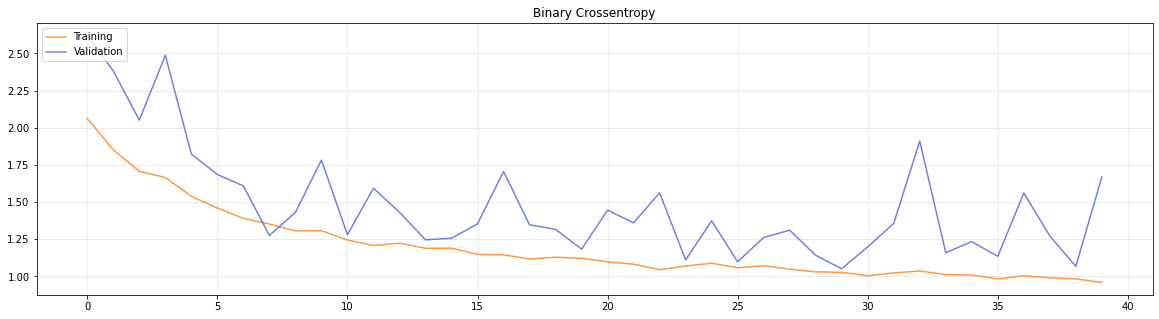

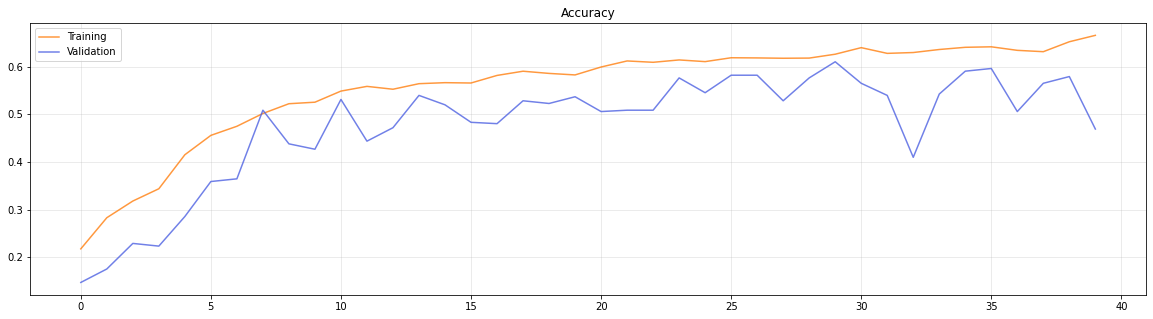

In [123]:
# Plot the training
plt.figure(figsize=(20,5))
plt.plot(history['loss'], label='Training', alpha=.8, color='#ff7f0e')
plt.plot(history['val_loss'], label='Validation', alpha=.8, color='#4D61E2')
plt.legend(loc='upper left')
plt.title('Binary Crossentropy')
plt.grid(alpha=.3)

plt.figure(figsize=(20,5))
plt.plot(history['accuracy'], label='Training', alpha=.8, color='#ff7f0e')
plt.plot(history['val_accuracy'], label='Validation', alpha=.8, color='#4D61E2')
plt.legend(loc='upper left')
plt.title('Accuracy')
plt.grid(alpha=.3)

plt.show()

In [124]:
# Save best epoch model
model.save("data_augmentation_experiments/CNN_Aug_Best")

In [125]:
# Evaluate on test
# Trainined with no data augmentation
model_noaug = tfk.models.load_model("data_augmentation_experiments/CNN_NoAug_Best")
model_noaug_test_metrics = model_noaug.evaluate(test_gen, return_dict=True)
# Trained with data augmentation
model_aug = tfk.models.load_model("data_augmentation_experiments/CNN_Aug_Best")
model_aug_test_metrics = model_aug.evaluate(test_gen, return_dict=True)

print()
print("Test metrics without data augmentation")
print(model_noaug_test_metrics)
print("Test metrics with data augmentation")
print(model_aug_test_metrics)

45/45 [==============================] - 1s 16ms/step - loss: 1.1845 - accuracy: 0.6184

Test metrics without data augmentation
{'loss': 1.4456297159194946, 'accuracy': 0.6490250825881958}
Test metrics with data augmentation
{'loss': 1.1844855546951294, 'accuracy': 0.6183844208717346}


# Visualize the activations

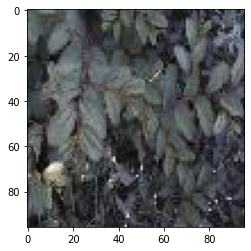

In [126]:
# Get sample batch
batch = next(test_gen)[0]

# Get first image
image = batch[3] # batch size = 8

fig = plt.figure(figsize=(6, 4))
plt.imshow(np.uint8(image*255))

In [127]:
# Get the activations (the output of each ReLU layer)
# We can do it by creating a new Model (activation_model) with the same input as 
# the original model and all the ReLU activations as output
layers = [layer.output for layer in model_aug.layers if isinstance(layer, tf.keras.layers.Conv2D)]
activation_model = tf.keras.Model(inputs=model_aug.input, outputs=layers)
# Finally we get the output feature maps (for each layer) given the imput test image
fmaps = activation_model.predict(tf.expand_dims(image, 0))

1/1 [==============================] - 0s 78ms/step


In [128]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
%matplotlib inline
def display_activation(fmaps, depth=0, first_n=-1): 
    # fmaps: list of all the feature maps for each layer
    # depth: the layer we want to visualize (an int in [0, network depth))
    # first_n: default '-1' means 'all activations'. Number of activations to be visualized. Note that for deep layers it could be a large number.

    fmaps = fmaps[depth] # get feature maps at the desired depth
    if first_n > 0:
      fmaps = fmaps[0, :, :, :first_n] 
    fmaps = tf.image.resize(fmaps, size=[128, 128]) # resize for visualization

    # Distribute on a grid for plotting
    col_size = 8
    row_size = fmaps.shape[-1] // 8
    fmap_channel=0
    fig = plt.figure(figsize=(30, 30))
    grid = ImageGrid(fig, 111,  # similar to subplot(111)
                    nrows_ncols=(row_size, col_size),  
                    axes_pad=0.1,  # pad between axes in inch.
                    )
    for row in range(0,row_size):
        for col in range(0,col_size):
            grid[fmap_channel].imshow(fmaps[0, :, :, fmap_channel], cmap='gray', aspect='auto')
            fmap_channel += 1
    plt.show()

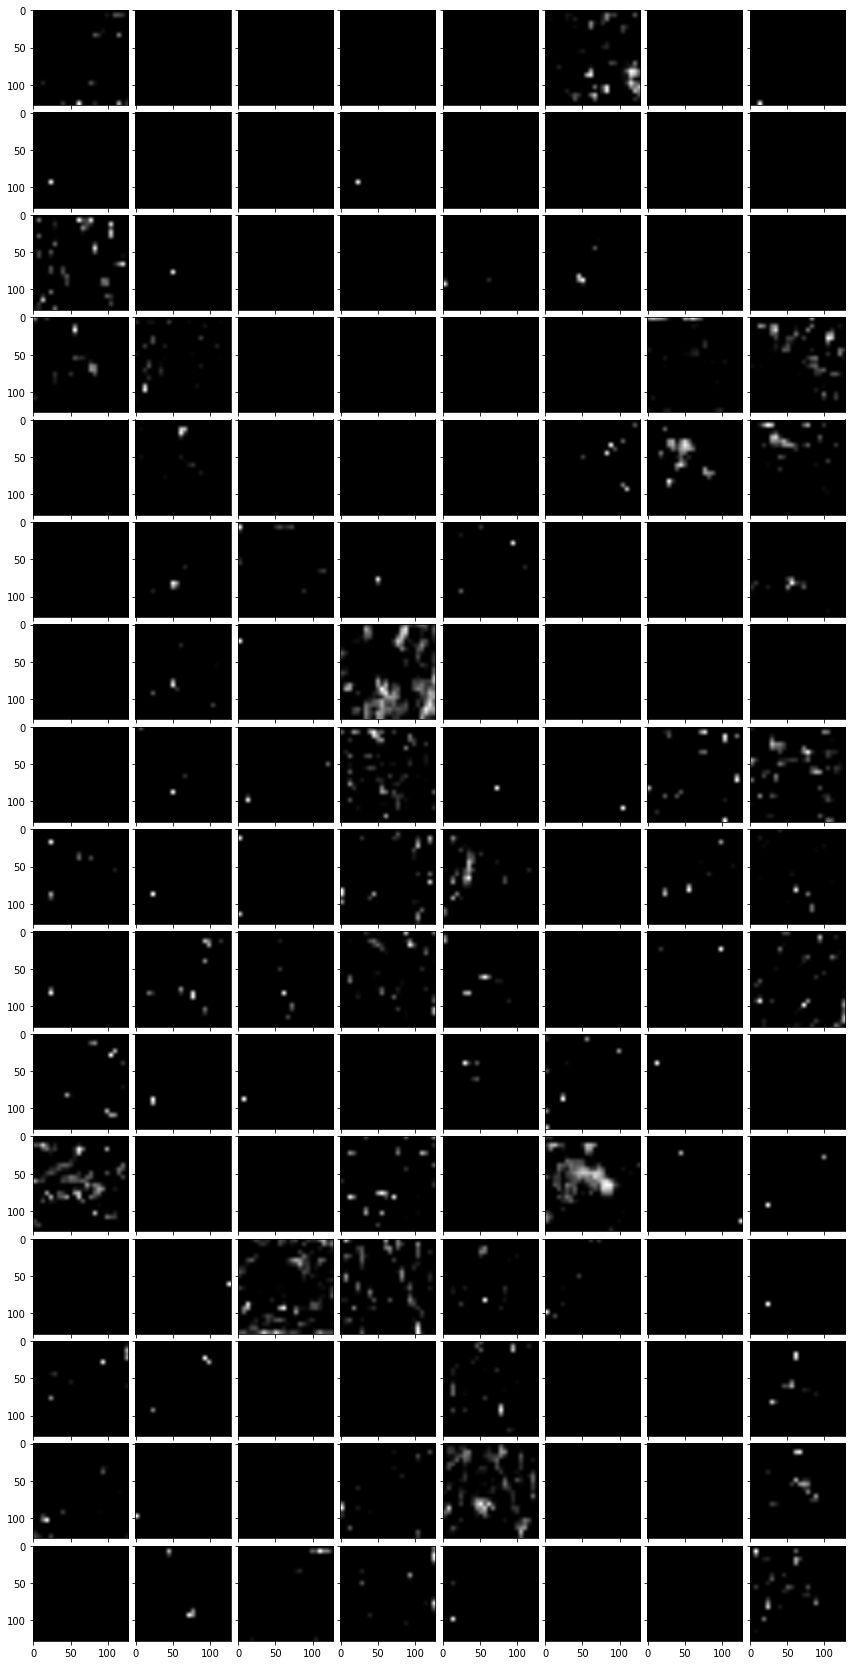

In [129]:
display_activation(fmaps=fmaps, depth=2, first_n=-1)